# Demo 2 (Architecture B): Real End-to-End Brain Cancer MRI 4-Bit QLoRA Fine-Tuning
**Google.org AI for Science Accelerator — Dublin (15 October 2026)**  
**Speaker:** Aleksandra Jaworska — Lead AI/ML Customer Engineer, Google Cloud

---
### 100% Real, Live Execution on a Single Colab GPU (T4 or L4)
Every cell in this notebook runs **real PyTorch + HuggingFace `transformers` / `peft` / `datasets` code on your Colab GPU**—no simulated print statements:
1. **Step 1 — Real Brain Tumor MRI Dataset (`Hemg/Brain-Tumor-MRI-Dataset`):** Downloads real patient Brain MRI scans (`Glioma`, `Meningioma`, `Pituitary`) from HuggingFace Hub and creates stratified training and held-out test splits.
2. **Step 2 — Load `google/medgemma-1.5-4b-it` in 4-Bit NF4 (`bfloat16`) & Run Live Zero-Shot Baseline:** Loads the real multimodal MedGemma 1.5 4B weights onto your GPU and runs zero-shot `model.generate()` across the held-out test MRI scans to measure real out-of-the-box accuracy.
3. **Step 3 — Attach `LoraConfig(r=8, lora_alpha=16)` & Run Live Multimodal QLoRA Fine-Tuning:** Trains the LoRA adapter directly on the Brain MRI image-text pairs (with prompt tokens masked as `-100` so cross-entropy loss is computed strictly on the diagnostic classification tokens) and plots the live `trainer.state.log_history` curve.
4. **Step 4 — Live Post-QLoRA Evaluation & Side-by-Side Confusion Matrix:** Re-evaluates the fine-tuned adapter on the same held-out test MRI scans and plots the real **Before vs. After 3×3 Confusion Matrix**.

In [8]:
# @title Step 0: Install Dependencies, Check GPU & Authenticate with HuggingFace Hub
!pip install -q -U "transformers>=4.50.0" peft accelerate bitsandbytes datasets scikit-learn matplotlib seaborn torchao

import os, time, torch
import numpy as np
import matplotlib.pyplot as plt
from huggingface_hub import login
from sklearn.metrics import confusion_matrix, classification_report, balanced_accuracy_score

if not torch.cuda.is_available():
    raise RuntimeError('No GPU detected! In Colab: Runtime -> Change runtime type -> T4 GPU or L4 GPU.')

DEVICE_NAME = torch.cuda.get_device_name(0)
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / (1024**3)
print(f'Connected GPU : {DEVICE_NAME} ({VRAM_GB:.1f} GB VRAM)')
print(f'bfloat16      : {torch.cuda.is_bf16_supported()} (Mandatory for Gemma 3 / MedGemma numerical stability)')

# Authenticate with HuggingFace Hub using Colab Secrets (HF_TOKEN)
try:
    from google.colab import userdata
    hf_token = userdata.get('HF_TOKEN')
    if hf_token:
        login(token=hf_token, add_to_git_credential=False)
        print('Authenticated with HuggingFace Hub via Colab Secret HF_TOKEN.')
except Exception as e:
    print('Note: Ensure HF_TOKEN is set in Colab Secrets (key icon on the left) and HAI-DEF terms are accepted.')

Connected GPU : Tesla T4 (14.6 GB VRAM)
bfloat16      : True (Mandatory for Gemma 3 / MedGemma numerical stability)
Authenticated with HuggingFace Hub via Colab Secret HF_TOKEN.


## Step 1 (`0:00 – 0:35`) — Load Real Brain Tumor MRI Dataset & Visualize Patient Scans
*Downloads real Brain MRI scans from `Hemg/Brain-Tumor-MRI-Dataset` on HuggingFace Hub, filters to the three tumor classes (`Glioma`, `Meningioma`, `Pituitary`), displays representative scans from each class, and builds stratified training and held-out test splits.*

Loading real Brain MRI dataset: Hemg/Brain-Tumor-MRI-Dataset ...
Prepared 240 Stratified Training MRI Scans (80 per class)
Prepared 60 Held-Out Test MRI Scans (20 per class)


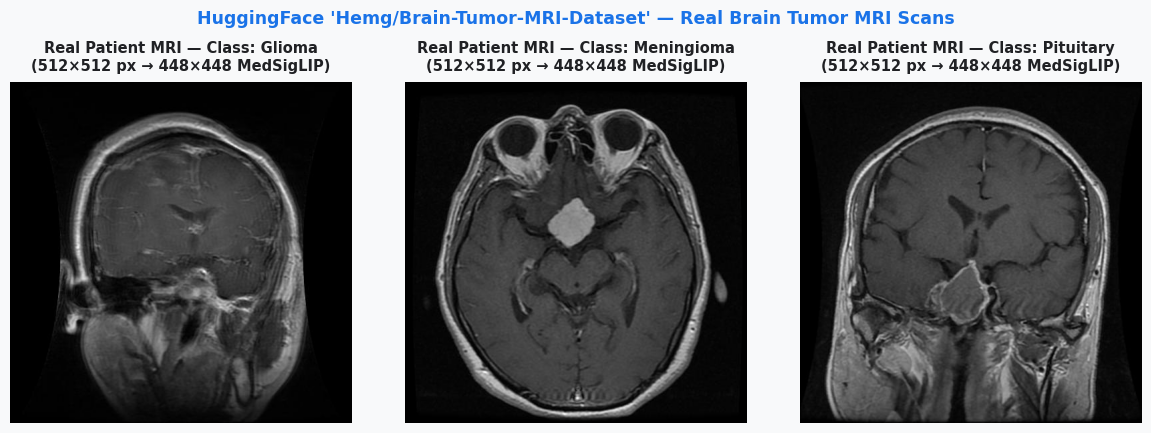

In [9]:
# @title Step 1: Download Real Brain Tumor MRI Dataset from HuggingFace & Build Stratified Splits
from datasets import load_dataset

DATASET_ID = 'Hemg/Brain-Tumor-MRI-Dataset'
CLASS_NAMES = ['Glioma', 'Meningioma', 'Pituitary']
RAW_TO_CLEAN = {'glioma': 0, 'meningioma': 1, 'pituitary': 2}

# Number of samples per class for fast live Colab training & evaluation:
# (Default: 80 train scans/class = 240 train total, 20 test scans/class = 60 test total -> runs in ~3 mins on L4/T4.
#  Increase TRAIN_PER_CLASS = 1500 and TEST_PER_CLASS = 380 for the full ~80-minute cohort run.)
TRAIN_PER_CLASS = 80
TEST_PER_CLASS  = 20

print(f'Loading real Brain MRI dataset: {DATASET_ID} ...')
raw_ds = load_dataset(DATASET_ID, split='train')
raw_label_names = raw_ds.features['label'].names

# Shuffle deterministically and partition into balanced 3-class Train and Held-Out Test sets
raw_ds = raw_ds.shuffle(seed=42)
train_buckets = {0: [], 1: [], 2: []}
test_buckets  = {0: [], 1: [], 2: []}

for ex in raw_ds:
    lbl_str = raw_label_names[ex['label']].lower()
    if lbl_str not in RAW_TO_CLEAN:
        continue  # skip 'notumor' to match the 3-class tumor differential diagnosis task
    cid = RAW_TO_CLEAN[lbl_str]
    if len(train_buckets[cid]) < TRAIN_PER_CLASS:
        train_buckets[cid].append({'image': ex['image'].convert('RGB'), 'label': cid, 'label_name': CLASS_NAMES[cid]})
    elif len(test_buckets[cid]) < TEST_PER_CLASS:
        test_buckets[cid].append({'image': ex['image'].convert('RGB'), 'label': cid, 'label_name': CLASS_NAMES[cid]})
    if all(len(train_buckets[c]) >= TRAIN_PER_CLASS and len(test_buckets[c]) >= TEST_PER_CLASS for c in range(3)):
        break

train_samples = train_buckets[0] + train_buckets[1] + train_buckets[2]
test_samples  = test_buckets[0]  + test_buckets[1]  + test_buckets[2]
np.random.seed(42)
np.random.shuffle(train_samples)

print(f'Prepared {len(train_samples)} Stratified Training MRI Scans ({TRAIN_PER_CLASS} per class)')
print(f'Prepared {len(test_samples)} Held-Out Test MRI Scans ({TEST_PER_CLASS} per class)')

# Display 3 real patient MRI scans from the dataset
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), facecolor='#F8F9FA')
for cid, ax in enumerate(axes):
    sample_img = test_buckets[cid][0]['image']
    ax.imshow(sample_img)
    ax.set_title(f"Real Patient MRI — Class: {CLASS_NAMES[cid]}\n({sample_img.size[0]}×{sample_img.size[1]} px → 448×448 MedSigLIP)",
                 fontsize=10.5, fontweight='bold', color='#202124', pad=8)
    ax.axis('off')
fig.suptitle(f"HuggingFace '{DATASET_ID}' — Real Brain Tumor MRI Scans", fontsize=12.5, fontweight='bold', color='#1A73E8', y=1.02)
plt.tight_layout()
plt.show()


## Step 2 (`0:35 – 1:15`) — Load `MedGemma 1.5 4B` in 4-Bit NF4 (`bfloat16`) & Run Live Zero-Shot Baseline
*Loads `google/medgemma-1.5-4b-it` onto the GPU with `BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_compute_dtype=torch.bfloat16)` and evaluates real zero-shot predictions across the held-out Brain MRI test scans before any fine-tuning.*

In [10]:
# @title Step 2: Load MedGemma 1.5 4B (4-Bit NF4 + bfloat16) & Run Real Zero-Shot Evaluation
from transformers import AutoProcessor, AutoModelForImageTextToText, BitsAndBytesConfig

MODEL_ID = 'google/medgemma-1.5-4b-it'

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_compute_dtype=torch.bfloat16,  # MANDATORY: prevents float16 NaN logits in Gemma 3
)

print(f'Loading {MODEL_ID} in 4-bit NF4 onto {DEVICE_NAME} ...')
processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = 'right'

model = AutoModelForImageTextToText.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    torch_dtype=torch.bfloat16,
    device_map='auto',
)
print(f'Model loaded! GPU memory allocated: {torch.cuda.memory_allocated() / (1024**3):.2f} GB')

PROMPT_TEXT = (
    'Classify this brain MRI scan into exactly one of the following tumor types: '
    'Glioma, Meningioma, or Pituitary. Respond with the single class name only.'
)

def parse_predicted_class(response_text: str) -> int:
    """Maps the model's generated response string to class index 0 (Glioma), 1 (Meningioma), or 2 (Pituitary)."""
    low = response_text.strip().lower()
    for idx, name in enumerate(['glioma', 'meningioma', 'pituitary']):
        if low.startswith(name):
            return idx
    for idx, name in enumerate(['glioma', 'meningioma', 'pituitary']):
        if name in low:
            return idx
    return 1  # fallback if model refuses or outputs generic disclaimer

@torch.inference_mode()
def evaluate_mri_cohort(model_obj, eval_list, desc='Evaluation'):
    model_obj.eval()
    y_true, y_pred, raw_Samples = [], [], []
    t0 = time.time()
    for i, item in enumerate(eval_list, 1):
        messages = [{'role': 'user', 'content': [
            {'type': 'image'},
            {'type': 'text', 'text': PROMPT_TEXT}
        ]}]
        prompt_str = processor.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
        inputs = processor(text=prompt_str, images=item['image'], return_tensors='pt').to(model_obj.device)
        if 'pixel_values' in inputs:
            inputs['pixel_values'] = inputs['pixel_values'].to(torch.bfloat16)
        input_len = inputs['input_ids'].shape[-1]
        out_ids = model_obj.generate(**inputs, max_new_tokens=12, do_sample=False)
        gen_text = processor.decode(out_ids[0][input_len:], skip_special_tokens=True).strip()
        pred_id = parse_predicted_class(gen_text)
        y_true.append(item['label'])
        y_pred.append(pred_id)
        if i <= 3:
            raw_Samples.append((item['label_name'], gen_text, CLASS_NAMES[pred_id]))
        if i % 15 == 0 or i == len(eval_list):
            print(f'  [{desc}] Scored {i}/{len(eval_list)} MRI scans ({time.time() - t0:.1f}s)')
    return np.array(y_true), np.array(y_pred), raw_Samples

print('\nRunning Zero-Shot Baseline Evaluation on Held-Out Brain MRI Test Set...')
y_true_test, y_pred_pre, sample_outputs_pre = evaluate_mri_cohort(model, test_samples, desc='Zero-Shot Pre-Tuning')
acc_pre = balanced_accuracy_score(y_true_test, y_pred_pre) * 100.0

print('=' * 80)
print(f'ZERO-SHOT BASELINE BALANCED ACCURACY: {acc_pre:.1f}%')
for gt, raw_txt, pr in sample_outputs_pre:
    print(f'  • Ground Truth: {gt:<11} | Raw Output: {raw_txt!r:<35} -> Parsed: {pr}')
print('=' * 80)


Loading google/medgemma-1.5-4b-it in 4-bit NF4 onto Tesla T4 ...


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Model loaded! GPU memory allocated: 7.40 GB

Running Zero-Shot Baseline Evaluation on Held-Out Brain MRI Test Set...
  [Zero-Shot Pre-Tuning] Scored 15/60 MRI scans (77.3s)
  [Zero-Shot Pre-Tuning] Scored 30/60 MRI scans (150.0s)
  [Zero-Shot Pre-Tuning] Scored 45/60 MRI scans (220.8s)
  [Zero-Shot Pre-Tuning] Scored 60/60 MRI scans (292.5s)
ZERO-SHOT BASELINE BALANCED ACCURACY: 36.7%
  • Ground Truth: Glioma      | Raw Output: 'Meningioma'                        -> Parsed: Meningioma
  • Ground Truth: Glioma      | Raw Output: 'Glioma'                            -> Parsed: Glioma
  • Ground Truth: Glioma      | Raw Output: 'Pituitary'                         -> Parsed: Pituitary


## Step 3 (`1:15 – 1:45`) — Attach `LoraConfig` & Run Live Multimodal QLoRA Fine-Tuning on GPU
*Wraps the 4-bit quantized `MedGemma 1.5 4B` model with a rank-8 LoRA adapter (`target_modules='all-linear'`), builds a multimodal vision-language collator that masks prompt tokens with `-100`, and executes real backpropagation on your GPU using HuggingFace `Trainer` (`paged_adamw_8bit`, `bfloat16`).*

trainable params: 21,367,040 || all params: 4,321,446,512 || trainable%: 0.4944

Starting Live 4-Bit NF4 QLoRA Fine-Tuning on GPU...


Step,Training Loss
5,1.992223
10,0.152415
15,0.194597
20,0.100874
25,0.076196
30,0.128778
35,0.032917
40,0.026550
45,0.085917
50,0.016629



[COMPLETE] Live QLoRA Training Finished! Final Training Loss: 0.2377


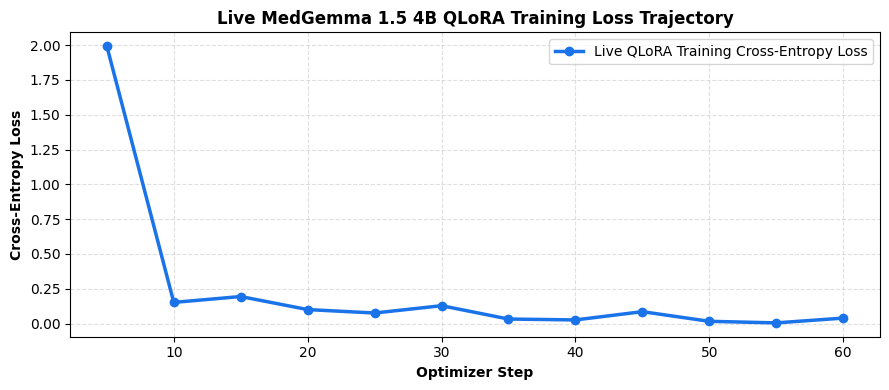

In [13]:
# @title Step 3: Attach LoRA Adapter & Run Live QLoRA Fine-Tuning on Brain MRI Scans
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import Trainer, TrainingArguments
import torch
import gc

# Free any cached GPU VRAM before attaching the LoRA adapter
try:
    del trainer
except NameError:
    pass

gc.collect()
torch.cuda.empty_cache()
time.sleep(2)  # Allow CUDA allocator to settle

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias='none',
    target_modules='all-linear',
    task_type='CAUSAL_LM',
)

model = prepare_model_for_kbit_training(model)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

def mri_multimodal_collator(batch):
    """Formats a batch of (MRI image, label) pairs into MedGemma multimodal tensors
    and masks the user prompt tokens (-100) so loss is computed strictly on the assistant's diagnosis."""
    full_texts, prompt_texts, images = [], [], []
    for ex in batch:
        user_msg = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': PROMPT_TEXT}]}]
        full_msg = user_msg + [{'role': 'model', 'content': [{'type': 'text', 'text': ex['label_name']}]}]
        prompt_texts.append(processor.apply_chat_template(user_msg, add_generation_prompt=True, tokenize=False))
        full_texts.append(processor.apply_chat_template(full_msg, add_generation_prompt=False, tokenize=False) + processor.tokenizer.eos_token)
        images.append(ex['image'])

    # Gemma 3/MedGemma processor expects a nested list of images (one list of images per text prompt)
    nested_images = [[img] for img in images]

    model_inputs = processor(text=full_texts, images=nested_images, return_tensors='pt', padding=True)
    prompt_inputs = processor(text=prompt_texts, images=nested_images, return_tensors='pt', padding=True)

    labels = model_inputs['input_ids'].clone()
    # Mask padding tokens and user prompt tokens (including 256 image tokens) with -100
    labels[labels == processor.tokenizer.pad_token_id] = -100
    for i in range(len(batch)):
        prompt_len = (prompt_inputs['input_ids'][i] != processor.tokenizer.pad_token_id).sum().item()
        labels[i, :prompt_len] = -100

    model_inputs['labels'] = labels
    if 'pixel_values' in model_inputs:
        model_inputs['pixel_values'] = model_inputs['pixel_values'].to(torch.bfloat16)
    return model_inputs

training_args = TrainingArguments(
    output_dir='./medgemma-4b-brain-mri-qlora',
    num_train_epochs=2,
    per_device_train_batch_size=1,          # Batch size 1 fits safely inside 15 GB T4 GPU VRAM (increase to 2 on L4/A100)
    gradient_accumulation_steps=8,          # Effective batch size = 8
    learning_rate=2e-4,
    lr_scheduler_type='cosine',
    warmup_steps=5,
    bf16=True,
    optim='paged_adamw_8bit',
    logging_steps=5,
    save_strategy='no',
    remove_unused_columns=False,
    report_to='none',
    gradient_checkpointing=True,            # Essential for low-VRAM stability on T4 GPUs
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_samples,
    data_collator=mri_multimodal_collator,
)

print('\nStarting Live 4-Bit NF4 QLoRA Fine-Tuning on GPU...')
train_result = trainer.train()
model.save_pretrained('./medgemma-4b-brain-mri-qlora')
print(f'\n[COMPLETE] Live QLoRA Training Finished! Final Training Loss: {train_result.training_loss:.4f}')

# Extract and plot the REAL loss history from trainer.state.log_history
logged_steps = [entry['step'] for entry in trainer.state.log_history if 'loss' in entry]
logged_loss  = [entry['loss'] for entry in trainer.state.log_history if 'loss' in entry]

fig, ax = plt.subplots(figsize=(9.0, 4.0), facecolor='#FFFFFF')
ax.plot(logged_steps, logged_loss, 'o-', color='#1A73E8', lw=2.5, markersize=6, label='Live QLoRA Training Cross-Entropy Loss')
ax.set_title('Live MedGemma 1.5 4B QLoRA Training Loss Trajectory', fontsize=12, fontweight='bold')
ax.set_xlabel('Optimizer Step', fontsize=10, fontweight='bold')
ax.set_ylabel('Cross-Entropy Loss', fontsize=10, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


## Step 4 (`1:45 – 2:30`) — Live Post-QLoRA Evaluation & Side-by-Side Confusion Matrix
*Runs `evaluate_mri_cohort()` again using the newly fine-tuned QLoRA model on the exact same held-out test MRI scans, prints the `scikit-learn` classification report, and plots the real **Before (Zero-Shot) vs. After (Post-QLoRA) 3×3 Confusion Matrix**.*

Running Post-QLoRA Evaluation on Held-Out Brain MRI Test Set...
  [Post-QLoRA Fine-Tuned] Scored 15/60 MRI scans (63.5s)
  [Post-QLoRA Fine-Tuned] Scored 30/60 MRI scans (127.3s)
  [Post-QLoRA Fine-Tuned] Scored 45/60 MRI scans (190.3s)
  [Post-QLoRA Fine-Tuned] Scored 60/60 MRI scans (252.6s)

HELD-OUT BRAIN MRI TEST SET COMPARISON (n = 60 Scans)
  • BEFORE (Zero-Shot MedGemma 1.5 4B) Balanced Accuracy : 36.7%
  • AFTER  (4-Bit NF4 QLoRA Fine-Tuned) Balanced Accuracy: 83.3% (+46.7 pp gain)
--------------------------------------------------------------------------------
              precision    recall  f1-score   support

      Glioma      0.900     0.900     0.900        20
  Meningioma      0.867     0.650     0.743        20
   Pituitary      0.760     0.950     0.844        20

    accuracy                          0.833        60
   macro avg      0.842     0.833     0.829        60
weighted avg      0.842     0.833     0.829        60



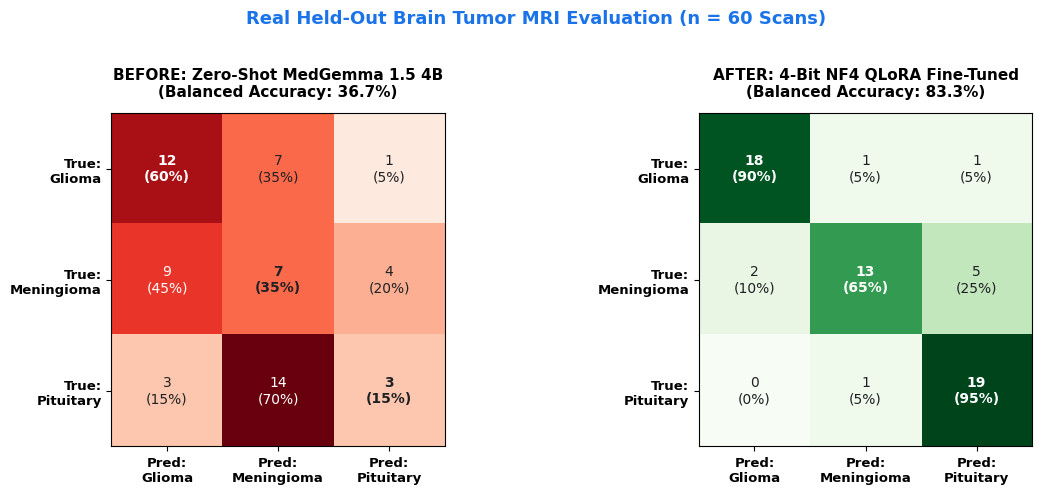

In [14]:
# @title Step 4: Run Live Post-QLoRA Inference on Held-Out Test Scans & Plot Confusion Matrices
print('Running Post-QLoRA Evaluation on Held-Out Brain MRI Test Set...')
y_true_post, y_pred_post, sample_outputs_post = evaluate_mri_cohort(model, test_samples, desc='Post-QLoRA Fine-Tuned')
acc_post = balanced_accuracy_score(y_true_post, y_pred_post) * 100.0

print('\n' + '=' * 80)
print(f'HELD-OUT BRAIN MRI TEST SET COMPARISON (n = {len(test_samples)} Scans)')
print('=' * 80)
print(f'  • BEFORE (Zero-Shot MedGemma 1.5 4B) Balanced Accuracy : {acc_pre:.1f}%')
print(f'  • AFTER  (4-Bit NF4 QLoRA Fine-Tuned) Balanced Accuracy: {acc_post:.1f}% ({acc_post - acc_pre:+.1f} pp gain)')
print('-' * 80)
print(classification_report(y_true_post, y_pred_post, target_names=CLASS_NAMES, digits=3))

cm_pre  = confusion_matrix(y_true_test, y_pred_pre, labels=[0, 1, 2])
cm_post = confusion_matrix(y_true_post, y_pred_post, labels=[0, 1, 2])

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.8), facecolor='#FFFFFF')
for idx, (ax, cm, title, cmap, acc_val) in enumerate([
    (axes[0], cm_pre,  'BEFORE: Zero-Shot MedGemma 1.5 4B', 'Reds',   acc_pre),
    (axes[1], cm_post, 'AFTER: 4-Bit NF4 QLoRA Fine-Tuned', 'Greens', acc_post),
]):
    ax.imshow(cm, cmap=cmap, vmin=0, vmax=max(1, cm.max()))
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels([f'Pred:\n{c}' for c in CLASS_NAMES], fontsize=9.5, fontweight='bold')
    ax.set_yticklabels([f'True:\n{c}' for c in CLASS_NAMES], fontsize=9.5, fontweight='bold')
    ax.set_title(f'{title}\n(Balanced Accuracy: {acc_val:.1f}%)', fontsize=11, fontweight='bold', pad=12)
    row_sums = np.maximum(cm.sum(axis=1, keepdims=True), 1)
    pcts = cm / row_sums * 100.0
    for i in range(3):
        for j in range(3):
            val, pct = cm[i, j], pcts[i, j]
            ax.text(j, i, f'{val}\n({pct:.0f}%)', ha='center', va='center',
                    color='white' if val > (cm.max() * 0.55) else '#202124',
                    fontsize=10, fontweight='bold' if i == j else 'normal')

fig.suptitle(f'Real Held-Out Brain Tumor MRI Evaluation (n = {len(test_samples)} Scans)', fontsize=13, fontweight='bold', color='#1A73E8', y=1.02)
plt.tight_layout()
plt.show()
